# 1. Stock Market Predictor

In [2]:
!pip install yfinance

In [3]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

df = yf.download('^NSEI', start='2016-01-01', end='2026-11-01')

/tmp/ipykernel_31133/3849075907.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download('^NSEI', start='2016-01-01', end='2026-11-01')
[*********************100%***********************]  1 of 1 completed


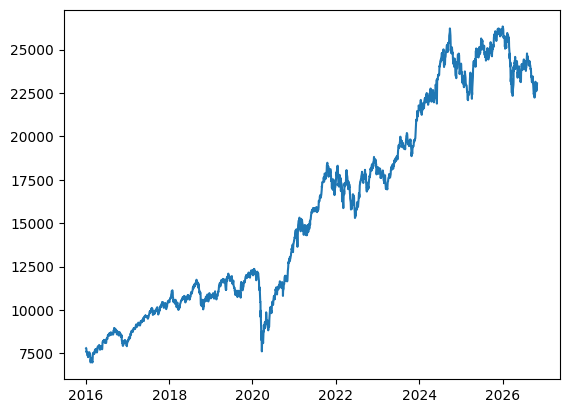

In [4]:
data = df[['Close']]

plt.plot(data)

In [5]:
train_data = data[data.index.year < 2026].values
test_data = data[data.index.year > 2025].values

In [6]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

train_data = scaler.fit_transform(train_data)
test_data = scaler.transform(test_data)

# Creating 60-Days Sliding Window
time_step = 60
X_train, y_train = [], []
X_test, y_test = [], []

for i in range(time_step, len(train_data)):
  X_train.append(train_data[i-time_step:i, 0])
  y_train.append(train_data[i, 0])

for i in range(time_step, len(test_data)):
  X_test.append(test_data[i - time_step : i, 0])
  y_test.append(test_data[i, 0])

# Convert to numpy arrays
X_train, y_train = np.array(X_train), np.array(y_train)
X_test, y_test = np.array(X_test), np.array(y_test)

# Reshape input to be [samples, time steps, features] required for LSTM
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

In [7]:
X_train.shape, X_test.shape

((2404, 60, 1), (144, 60, 1))

In [8]:
import tensorflow as tf
from keras import layers, Sequential

model = Sequential([
    layers.Input(shape = (time_step,1)),

    # Setting return_sequences=True allows the next LSTM layer to receive the sequence
    layers.LSTM(units = 64, return_sequences=True),
    layers.Dropout(0.2),

    # The last LSTM layer can have return_sequences=False (default)
    layers.LSTM(units = 64, return_sequences=False),
    layers.Dropout(0.2),

    layers.Dense(1, activation = 'linear')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,985 (195.25 KB)

 Trainable params: 49,985 (195.25 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(
    optimizer = 'adam',
    loss = 'mean_squared_error',
)

model.fit(X_train, y_train, epochs = 25, batch_size = 64, validation_split=0.1)

Epoch 1/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - loss: 0.0198 - val_loss: 0.0090
Epoch 2/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0025 - val_loss: 0.0016
Epoch 3/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0021 - val_loss: 0.0012
Epoch 4/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0016 - val_loss: 8.4497e-04
Epoch 5/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0017 - val_loss: 4.7203e-04
Epoch 6/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0016 - val_loss: 4.7011e-04
Epoch 7/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0015 - val_loss: 0.0020
Epoch 8/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0016 - val_loss: 4.4591e-04
Epoch 9/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0016 - val_loss: 4.3758e-04
Epoch 10/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0014 - val_loss: 0.0021
Epoch 11/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0014 - val_loss: 4.1412e-04
Epoch 12/25
34/34 ━━━━━━━━━━━━━━━━━━━━ 

# 2. Next Word Generator

In [10]:
file = open("/content/blue_castle.txt", "r", encoding = "utf8" )

#store file in list
lines = []
for i in file:
     lines.append(i)

#Convert list to string
data = ""
for i in lines:
    data = '  '. join(lines)

#replace unnecessary stuff with space
data = data.replace('\n', '').replace('\r', '').replace('\ufeff', '').replace('“','').replace('”','')  #new line, carriage return, unicode character --> replace by space

#remove unnecessary spaces
data = data.split()
data = ' '.join(data)
data[:500]

'The Project Gutenberg eBook of The Blue Castle, by Lucy Maud Montgomery This eBook is for the use of anyone anywhere in the United States and most other parts of the world at no cost and with almost no restrictions whatsoever. You may copy it, give it away or re-use it under the terms of the Project Gutenberg License included with this eBook or online at www.gutenberg.org. If you are not located in the United States, you will have to check the laws of the country where you are located before usi'

### Standard NLP Next-Word Prediction Pipeline
Let's implement the standard pipeline with memory-efficient sparse cross-entropy and correct input dimensions.

In [11]:
import numpy as np
import tensorflow as tf
from keras import layers, Sequential

# 1. Clean and tokenize text into single words
words = data.lower().split()

# 2. Re-initialize and adapt our tokenizer on the word sequences
MAX_LEN = 10
tokenizer = layers.TextVectorization(
    max_tokens=10000,
    standardize="lower_and_strip_punctuation"
)
tokenizer.adapt(words)

VOCAB_SIZE = len(tokenizer.get_vocabulary())
print(f"Vocabulary size: {VOCAB_SIZE}")

# Convert all words to integer IDs
all_token_ids = tokenizer(words).numpy().flatten()

# 3. Sliding Window Creation
X_new = []
y_new = []

for i in range(MAX_LEN, len(all_token_ids)):
    X_new.append(all_token_ids[i-MAX_LEN:i])
    y_new.append(all_token_ids[i])

X_new = np.array(X_new)
y_new = np.array(y_new)

print(f"Inputs shape: {X_new.shape}")
print(f"Targets shape: {y_new.shape}")

Vocabulary size: 8621
Inputs shape: (71304, 10)
Targets shape: (71304,)


In [20]:
EMBEDDING_DIM = 64
LSTM_UNITS = 1024

# 4. Correct model expecting Integer IDs as inputs
nlp_model = Sequential([
    # Input is a sequence of integers of length MAX_LEN
    layers.Input(shape=(MAX_LEN,), dtype='int32'),

    # Embeddings maps integer tokens to continuous vector spaces
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM),

    # LSTM Layers
    layers.LSTM(units=LSTM_UNITS, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(units=LSTM_UNITS, return_sequences=False),
    layers.Dropout(0.2),

    # Dense output with Softmax matching vocabulary size
    layers.Dense(units=VOCAB_SIZE, activation='softmax')
])

# Using 'sparse_categorical_crossentropy' avoids needing one-hot matrices
nlp_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

nlp_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 10, 64)         │       551,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_8 (LSTM)                   │ (None, 10, 1024)       │     4,460,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 10, 1024)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_9 (LSTM)                   │ (None, 1024)           │     8,392,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8621)           │     8,836,525 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,241,517 (84.84 MB)

 Trainable params: 22,241,517 (84.84 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# 5. Training the model
nlp_model.fit(X_new, y_new, epochs=10, batch_size=128, validation_split=0.2)

Epoch 1/10
446/446 ━━━━━━━━━━━━━━━━━━━━ 29s 59ms/step - accuracy: 0.0374 - loss: 6.8046 - val_accuracy: 0.0489 - val_loss: 6.9634
Epoch 2/10
446/446 ━━━━━━━━━━━━━━━━━━━━ 25s 57ms/step - accuracy: 0.0490 - loss: 6.4605 - val_accuracy: 0.0542 - val_loss: 7.0324
Epoch 3/10
446/446 ━━━━━━━━━━━━━━━━━━━━ 24s 54ms/step - accuracy: 0.0601 - loss: 6.2403 - val_accuracy: 0.0598 - val_loss: 7.0010
Epoch 4/10
446/446 ━━━━━━━━━━━━━━━━━━━━ 25s 55ms/step - accuracy: 0.0711 - loss: 6.0497 - val_accuracy: 0.0628 - val_loss: 7.0507
Epoch 5/10
446/446 ━━━━━━━━━━━━━━━━━━━━ 25s 56ms/step - accuracy: 0.0775 - loss: 5.9450 - val_accuracy: 0.0624 - val_loss: 7.2156
Epoch 6/10
446/446 ━━━━━━━━━━━━━━━━━━━━ 25s 55ms/step - accuracy: 0.0713 - loss: 6.0982 - val_accuracy: 0.0581 - val_loss: 7.2385
Epoch 7/10
446/446 ━━━━━━━━━━━━━━━━━━━━ 25s 55ms/step - accuracy: 0.0789 - loss: 5.9350 - val_accuracy: 0.0665 - val_loss: 7.2711
Epoch 8/10
446/446 ━━━━━━━━━━━━━━━━━━━━ 25s 56ms/step - accuracy: 0.0869 - loss: 5.7915 - 

### 6. Making Predictions & Generating Text
Now we'll create a function that takes a seed text, processes it exactly like our training data, and predicts the next word (or generates a whole sequence of words).

In [26]:
def generate_text(seed_text, next_words=10):
    # Get vocabulary to convert token IDs back to actual words
    vocab = tokenizer.get_vocabulary()

    output_text = seed_text

    for _ in range(next_words):
        # Tokenize the current seed text
        tokenized_input = tokenizer([output_text]).numpy().flatten()

        # Keep only the last MAX_LEN tokens to match model input shape
        if len(tokenized_input) > MAX_LEN:
            tokenized_input = tokenized_input[-MAX_LEN:]
        elif len(tokenized_input) < MAX_LEN:
            # Pad with zeros if the input is too short
            tokenized_input = np.pad(tokenized_input, (MAX_LEN - len(tokenized_input), 0), 'constant')

        # Reshape to batch size of 1 -> (1, MAX_LEN)
        tokenized_input = np.reshape(tokenized_input, (1, MAX_LEN))

        # Predict probability distribution for the next word
        predictions = nlp_model.predict(tokenized_input, verbose=0)

        # Extract the index with the highest predicted probability
        predicted_id = np.argmax(predictions, axis=-1)[0]

        # Map index to word
        predicted_word = vocab[predicted_id]

        # Stop if we predict an out-of-vocabulary or padding token
        if predicted_word == "" or predicted_word == "[UNK]":
            break

        # Append the predicted word to our text sequence
        output_text += " " + predicted_word

    return output_text

# Example usage (Run after training completion):
demo_generation = generate_text("the blue castle was", next_words=5)
print(demo_generation)

the blue castle was a little castle and a
